<a href="https://colab.research.google.com/github/hilya-23/project_akhir_deeplearning_kelompok7/blob/main/Project_Akhir_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 0.1 Instalasi pustaka (jalankan sekali per sesi)
!pip -q install ultralytics torchmetrics pycocotools imagehash openpyxl

In [ ]:
import os

def cari_berkas(nama_target, folder_mulai='/content/drive/MyDrive'):
    print(f"Mencari '{nama_target}' di {folder_mulai}... Mohon tunggu.")
    ditemukan = []
    for root, dirs, files in os.walk(folder_mulai):
        for file in files:
            if nama_target.lower() in file.lower():
                path_lengkap = os.path.join(root, file)
                ditemukan.append(path_lengkap)
                print(f"-> Ditemukan: {path_lengkap}")
    if not ditemukan:
        print("Berkas tidak ditemukan. Pastikan nama berkas tepat atau sudah terunggah sempurna di Google Drive.")
    return ditemukan

hasil_pencarian = cari_berkas('TXL-PBC_Dataset-master.zip')

Mencari 'TXL-PBC_Dataset-master.zip' di /content/drive/MyDrive... Mohon tunggu.
-> Ditemukan: /content/drive/MyDrive/Project_Akhir_DeepLearning/TXL-PBC_Dataset-master.zip


In [ ]:
# 0.2 Konfigurasi — EDIT BAGIAN INI SAJA
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH    = '/content/drive/MyDrive/Project_Akhir_DeepLearning/TXL-PBC_Dataset-master.zip'   # zip dataset di Drive
PROJECT_DIR = '/content/drive/MyDrive/Hasil_Akhir'                    # folder kerja tim (output permanen, dibagi dengan Hilyatul)
OWNER       = 'Khofifah dan Hilyatul Abidah'
SEED        = 42

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 0.3 Import, seed, folder, ekstraksi dataset, versi pustaka
import os, json, random, time, shutil, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings('ignore')

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

PROJECT_DIR = Path(PROJECT_DIR)
WORK = Path('/content/work'); WORK.mkdir(parents=True, exist_ok=True)
DIRS = {k: PROJECT_DIR/k for k in ['splits', 'gt', 'predictions', 'weights', 'figures', 'logs']}
for d in DIRS.values(): d.mkdir(parents=True, exist_ok=True)
LOCAL_RUNS  = WORK/'runs'
LOG_CSV     = DIRS['logs']/'experiment_log.csv'     # log semua run (termasuk yang gagal)
RESULTS_CSV = DIRS['logs']/'results_eval.csv'       # hasil evaluasi (format sama utk YOLO dan Faster R-CNN)

# Memeriksa dan mengekstrak dataset secara aman
zip_path_obj = Path(ZIP_PATH)
if not zip_path_obj.exists():
    print(f"[ERROR] File dataset ZIP tidak ditemukan di jalur: {ZIP_PATH}")
    print("Silakan periksa kembali apakah file sudah diunggah dan variabel ZIP_PATH di sel 0.2 sudah benar!")
else:
    if not any(WORK.glob('**/TXL-PBC/data.yaml')):
        print(f"Mengekstrak dataset dari {ZIP_PATH}...")
        with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(WORK)

try:
    DATA_ROOT = next(WORK.glob('**/TXL-PBC/data.yaml')).parent
    print('DATA_ROOT :', DATA_ROOT)
except StopIteration:
    print("[ERROR] Berkas 'data.yaml' tidak ditemukan di folder ekstraksi. Proses ekstraksi mungkin gagal atau tidak lengkap.")

GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
print('GPU       :', GPU_NAME)
try:
    import ultralytics, torchmetrics
    print('torch', torch.__version__, '| ultralytics', ultralytics.__version__, '| torchmetrics', torchmetrics.__version__)
except Exception as e:
    print('versi pustaka tidak terbaca:', e)

def append_csv(path, row):
    df_new = pd.DataFrame([row])
    df = pd.concat([pd.read_csv(path), df_new], ignore_index=True) if Path(path).exists() else df_new
    df.to_csv(path, index=False)

def savefig(name):
    plt.savefig(DIRS['figures']/f'{name}.png', dpi=150, bbox_inches='tight')

DATA_ROOT : /content/work/TXL-PBC_Dataset-master/TXL-PBC
GPU       : Tesla T4
torch 2.14.1+cu130 | ultralytics 8.4.216 | torchmetrics 1.9.0


## 1. Audit dan Pipeline Data (K2)
Dataset TXL-PBC sudah berformat YOLO dan **sudah punya split resmi** (train/val/test) → dipakai apa adanya, tanpa diacak ulang.
ID kelas: `0 = WBC`, `1 = RBC`, `2 = Platelet`.

### 1.1 Inventaris berkas dan parsing anotasi

In [ ]:
SPLITS = ['train', 'val', 'test']
CLASS_NAMES  = ['WBC', 'RBC', 'Platelet']
CLASS_COLORS = {0: '#1f77b4', 1: '#d62728', 2: '#2ca02c'}

inv = {s: sorted(p.name for p in (DATA_ROOT/'images'/s).glob('*.png')) for s in SPLITS}

rows = []
for s in SPLITS:
    lbl = sorted((DATA_ROOT/'labels'/s).glob('*.txt'))
    missing = [n for n in inv[s] if not (DATA_ROOT/'labels'/s/(Path(n).stem + '.txt')).exists()]
    empty   = [f.name for f in lbl if f.stat().st_size == 0]
    rows.append(dict(split=s, n_images=len(inv[s]), n_label_files=len(lbl), citra_tanpa_label=len(missing), label_kosong=len(empty)))
print(pd.DataFrame(rows).to_string(index=False))
assert all(r['citra_tanpa_label'] == 0 for r in rows), 'Ada citra tanpa berkas label!'

for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    print(f'nama berkas sama {a}-{b}:', len(set(inv[a]) & set(inv[b])))

# parsing seluruh anotasi YOLO -> koordinat piksel (x1,y1,x2,y2)
recs, img_rows, bad_lines = [], [], 0
for s in SPLITS:
    for n in inv[s]:
        with Image.open(DATA_ROOT/'images'/s/n) as im: W, H = im.size
        img_rows.append(dict(split=s, image=n, image_w=W, image_h=H))
        for line in (DATA_ROOT/'labels'/s/(Path(n).stem + '.txt')).read_text().splitlines():
            p = line.split()
            if len(p) != 5: bad_lines += 1; continue
            c = int(float(p[0])); cx, cy, w, h = map(float, p[1:])
            x1, y1, x2, y2 = (cx - w/2)*W, (cy - h/2)*H, (cx + w/2)*W, (cy + h/2)*H
            recs.append(dict(split=s, image=n, cls=c, x1=x1, y1=y1, x2=x2, y2=y2, W=W, H=H))
ann = pd.DataFrame(recs)
oob = ((ann.x1 < -0.5) | (ann.y1 < -0.5) | (ann.x2 > ann.W + 0.5) | (ann.y2 > ann.H + 0.5)).sum()
ann['x1'] = ann.x1.clip(0, ann.W); ann['x2'] = ann.x2.clip(0, ann.W)
ann['y1'] = ann.y1.clip(0, ann.H); ann['y2'] = ann.y2.clip(0, ann.H)
ann['w_px'] = ann.x2 - ann.x1; ann['h_px'] = ann.y2 - ann.y1
ann['area'] = ann.w_px * ann.h_px
ann['cls_name'] = ann.cls.map(dict(enumerate(CLASS_NAMES)))

img_df = pd.DataFrame(img_rows)
meta = pd.read_excel(DATA_ROOT/'metadata_file.xlsx')[['New_Image_Name', 'Source_Dataset']]
meta.columns = ['image', 'source']
img_df = img_df.merge(meta, on='image', how='left')
ann = ann.merge(img_df[['image', 'source']], on='image', how='left')

print('\nbaris label tidak valid :', bad_lines)
print('kelas di luar {0,1,2}   :', int((~ann.cls.isin([0, 1, 2])).sum()))
print('box luas <= 0           :', int((ann.area <= 0).sum()))
print('box keluar batas (di-clip):', int(oob))
print('citra tanpa sumber (metadata):', int(img_df.source.isna().sum()))
print('total anotasi            :', len(ann))

# GT per split: {nama_citra: {'boxes': Nx4 (xyxy piksel), 'labels': N (0=WBC,1=RBC,2=Platelet)}}
GT = {s: {} for s in SPLITS}
for (s, n), g in ann.groupby(['split', 'image']):
    GT[s][n] = {'boxes': g[['x1', 'y1', 'x2', 'y2']].to_numpy(float), 'labels': g['cls'].to_numpy(int)}
for s in SPLITS:
    for n in inv[s]:
        GT[s].setdefault(n, {'boxes': np.zeros((0, 4)), 'labels': np.zeros((0,), int)})

split  n_images  n_label_files  citra_tanpa_label  label_kosong
train       882            882                  0             0
  val       252            252                  0             0
 test       126            126                  0             0
nama berkas sama train-val: 0
nama berkas sama train-test: 0
nama berkas sama val-test: 0

baris label tidak valid : 0
kelas di luar {0,1,2}   : 0
box luas <= 0           : 0
box keluar batas (di-clip): 0
citra tanpa sumber (metadata): 0
total anotasi            : 18143


### 1.2 Analisis data eksploratif (EDA)

cls_name  WBC    RBC  Platelet  Total
split                                
train     908  11220       382  12510
val       257   3383       112   3752
test      133   1699        49   1881

Proporsi (%):
cls_name  WBC   RBC  Platelet
split                        
train     7.3  89.7       3.1
val       6.8  90.2       3.0
test      7.1  90.3       2.6

Rasio RBC : WBC : Platelet (train) = 29.4 : 2.4 : 1


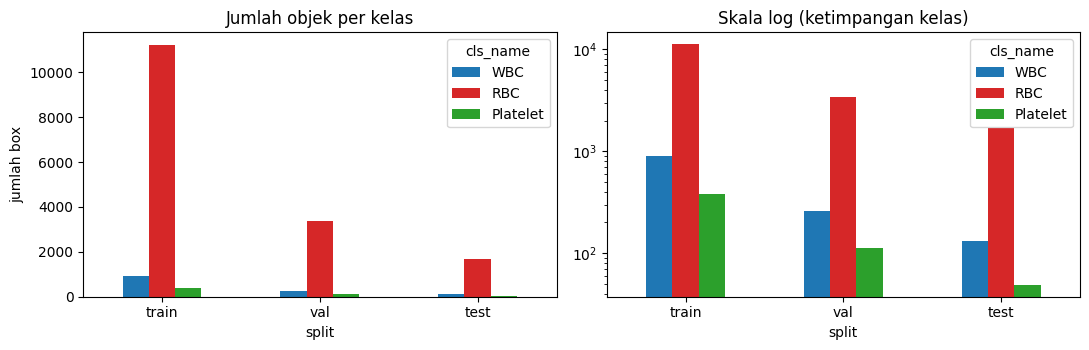

In [ ]:
# (a) Distribusi kelas per split
tab = pd.crosstab(ann.split, ann.cls_name).reindex(SPLITS)[CLASS_NAMES]
tab['Total'] = tab.sum(1)
print(tab.to_string())
print('\nProporsi (%):'); print((tab[CLASS_NAMES].div(tab.Total, axis=0) * 100).round(1).to_string())
print('\nRasio RBC : WBC : Platelet (train) = %.1f : %.1f : 1' % (tab.loc['train', 'RBC']/tab.loc['train', 'Platelet'], tab.loc['train', 'WBC']/tab.loc['train', 'Platelet']))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tab[CLASS_NAMES].plot.bar(ax=ax[0], color=[CLASS_COLORS[i] for i in range(3)], rot=0)
ax[0].set_title('Jumlah objek per kelas'); ax[0].set_ylabel('jumlah box')
tab[CLASS_NAMES].plot.bar(ax=ax[1], color=[CLASS_COLORS[i] for i in range(3)], rot=0, logy=True)
ax[1].set_title('Skala log (ketimpangan kelas)')
plt.tight_layout(); savefig('eda_distribusi_kelas'); plt.show()

split             test   train     val
WBC      count  126.00  882.00  252.00
         mean     1.06    1.03    1.02
         std      0.26    0.24    0.19
         min      1.00    0.00    0.00
         25%      1.00    1.00    1.00
         50%      1.00    1.00    1.00
         75%      1.00    1.00    1.00
         max      3.00    6.00    2.00
RBC      count  126.00  882.00  252.00
         mean    13.48   12.72   13.42
         std      4.70    4.22    4.93
         min      4.00    3.00    4.00
         25%     10.25   10.00   10.00
         50%     12.50   12.00   12.00
         75%     16.00   15.00   16.00
         max     26.00   27.00   30.00
Platelet count  126.00  882.00  252.00
         mean     0.39    0.43    0.44
         std      0.79    0.84    0.95
         min      0.00    0.00    0.00
         25%      0.00    0.00    0.00
         50%      0.00    0.00    0.00
         75%      1.00    1.00    1.00
         max      4.00    6.00    5.00

Citra TANPA platelet : 0

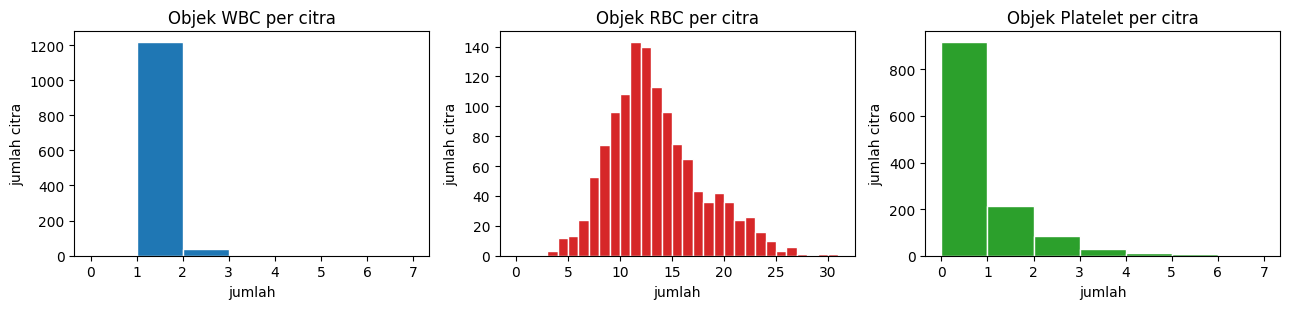

In [ ]:
# (b) Jumlah objek per citra per kelas  -> menentukan seberapa sulit penghitungan
cnt_img = ann.groupby(['image', 'cls']).size().unstack(fill_value=0).reindex(img_df.image, fill_value=0)
cnt_img.columns = CLASS_NAMES
cnt_img = cnt_img.join(img_df.set_index('image')[['split', 'source']])
print(cnt_img.groupby('split')[CLASS_NAMES].describe().T.round(2).to_string())
print('\nCitra TANPA platelet :', (cnt_img.Platelet == 0).mean().round(3), '| TANPA WBC :', (cnt_img.WBC == 0).mean().round(3))
print('Maks objek per citra :', cnt_img[CLASS_NAMES].max().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for i, c in enumerate(CLASS_NAMES):
    ax[i].hist(cnt_img[c], bins=range(0, int(cnt_img[c].max()) + 2), color=CLASS_COLORS[i], edgecolor='white')
    ax[i].set_title(f'Objek {c} per citra'); ax[i].set_xlabel('jumlah'); ax[i].set_ylabel('jumlah citra')
plt.tight_layout(); savefig('eda_objek_per_citra'); plt.show()

            count   mean   std   min    25%    50%    75%    max
cls_name                                                        
WBC        1298.0  190.8  69.2  69.0  133.1  184.1  254.0  374.7
RBC       16302.0   94.1  29.4  36.8   71.5   86.9  115.1  307.8
Platelet    543.0   35.7  10.8  16.0   29.4   33.5   40.0  109.5

Proporsi small / medium / large per kelas (%):
         WBC   RBC  Platelet
small    0.0   0.0      43.6
medium   6.0  57.9      56.2
large   94.0  42.1       0.2


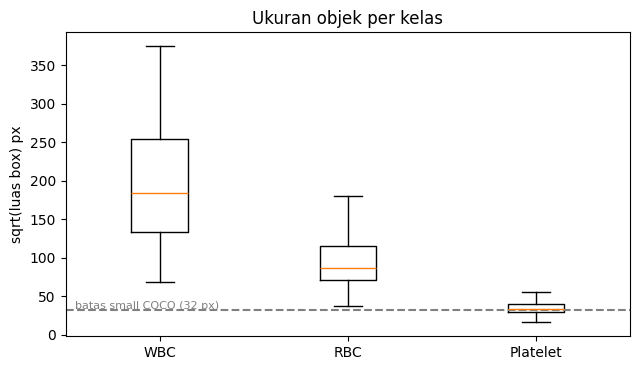

In [ ]:
# (c) Sebaran ukuran box (px, resolusi asli) — kunci untuk platelet sebagai objek kecil
ann['sqrt_area'] = np.sqrt(ann.area)
print(ann.groupby('cls_name').sqrt_area.describe().round(1).loc[CLASS_NAMES].to_string())
ann['small'] = ann.area < 32**2          # definisi COCO: area < 32x32 px
ann['medium'] = (ann.area >= 32**2) & (ann.area < 96**2)
print('\nProporsi small / medium / large per kelas (%):')
print(pd.DataFrame({c: [100*ann[ann.cls_name == c].small.mean(), 100*ann[ann.cls_name == c].medium.mean(),
                        100*(ann[ann.cls_name == c].area >= 96**2).mean()] for c in CLASS_NAMES},
                   index=['small', 'medium', 'large']).round(1).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.boxplot([ann[ann.cls_name == c].sqrt_area for c in CLASS_NAMES], showfliers=False)
ax.set_xticklabels(CLASS_NAMES)
ax.axhline(32, ls='--', c='gray'); ax.text(0.55, 33, 'batas small COCO (32 px)', fontsize=8, color='gray')
ax.set_ylabel('sqrt(luas box) px'); ax.set_title('Ukuran objek per kelas')
plt.tight_layout(); savefig('eda_ukuran_box'); plt.show()

In [ ]:
# (d) Ukuran citra dan sumber dataset asal (BCCD/BCDD/PBC/Raabin-WBC)
print(img_df.groupby(['image_w', 'image_h']).size().rename('n_citra').to_frame().to_string())
print('\nSumber x split:'); print(pd.crosstab(img_df.source, img_df.split).to_string())
print('\nRata-rata objek per citra menurut sumber:')
print(cnt_img.groupby('source')[CLASS_NAMES].mean().round(2).to_string())

                 n_citra
image_w image_h         
256     256          100
360     363          486
366     369           14
575     575          500
640     480          160

Sumber x split:
split       test  train  val
source                      
BCCD          18    101   41
BCDD          14     70   16
PBC           50    353   97
Raabin-WBC    44    358   98

Rata-rata objek per citra menurut sumber:
             WBC    RBC  Platelet
source                           
BCCD        1.02  19.87      1.04
BCDD        1.00  16.34      0.03
PBC         1.05  12.65      0.68
Raabin-WBC  1.02  10.33      0.06


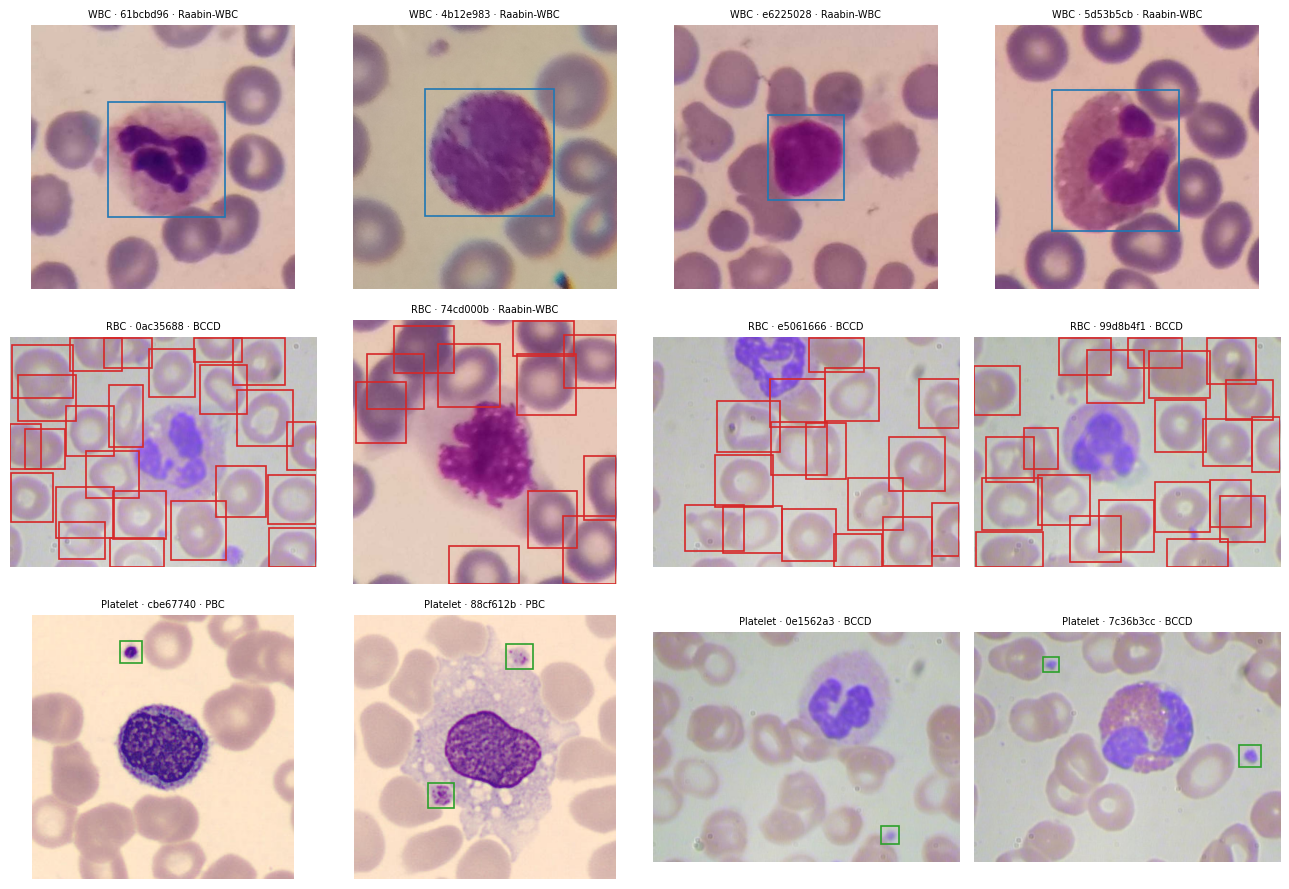

In [ ]:
# (e) Contoh visual per kelas (hanya box kelas tsb yang digambar)
def draw(ax, split, name, only_cls=None, lw=1.2, title=None):
    im = Image.open(DATA_ROOT/'images'/split/name).convert('RGB'); ax.imshow(im)
    g = GT[split][name]
    for b, c in zip(g['boxes'], g['labels']):
        if only_cls is not None and c != only_cls: continue
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec=CLASS_COLORS[int(c)], lw=lw))
    ax.set_title(title or f'{split}/{name[:8]}', fontsize=7); ax.axis('off')

rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for r, c in enumerate(range(3)):
    pool = cnt_img[(cnt_img[CLASS_NAMES[c]] > 0) & (cnt_img.split == 'train')].index.tolist()
    for k, n in enumerate(rng.choice(pool, 4, replace=False)):
        draw(axes[r, k], 'train', n, only_cls=c, title=f'{CLASS_NAMES[c]} · {n[:8]} · {img_df.set_index("image").loc[n, "source"]}')
plt.tight_layout(); savefig('eda_contoh_per_kelas'); plt.show()

### 1.3 Konversi anotasi + verifikasi visual (≥ 20 citra)
Label asli = YOLO (`cls cx cy w h` ternormalisasi). Untuk evaluator bersama dan Faster R-CNN (torchvision) dikonversi ke **`xyxy` piksel**.
Pemeriksaan: (1) jumlah box setelah konversi = jumlah baris label, (2) semua box di dalam citra, (3) **20 citra acak digambar ulang** — kotak harus menempel pada sel.

train baris label= 12510 | box GT= 12510 | cocok=True | semua di dalam citra=True
val   baris label=  3752 | box GT=  3752 | cocok=True | semua di dalam citra=True
test  baris label=  1881 | box GT=  1881 | cocok=True | semua di dalam citra=True


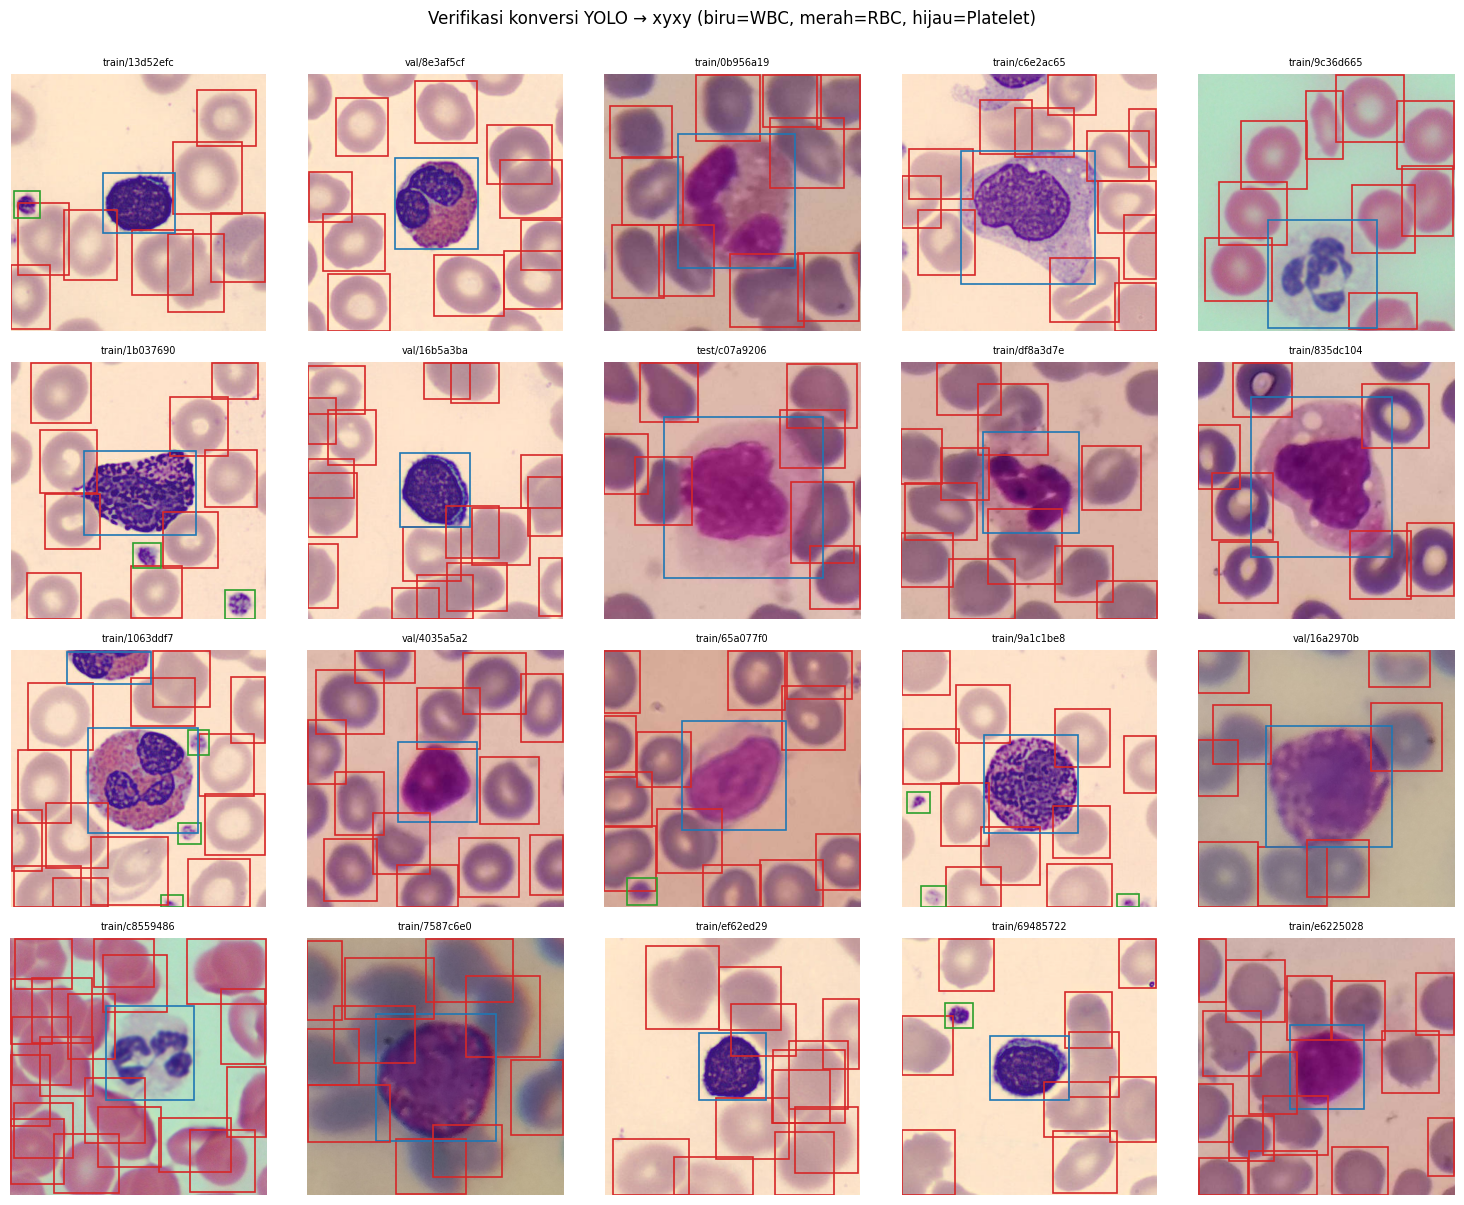

GT tersimpan di /content/drive/MyDrive/Hasil_Akhir/gt


In [ ]:
# (1)+(2) pemeriksaan programatik
for s in SPLITS:
    n_lines = sum(len([l for l in (DATA_ROOT/'labels'/s/(Path(n).stem + '.txt')).read_text().splitlines() if len(l.split()) == 5]) for n in inv[s])
    n_gt = sum(len(v['labels']) for v in GT[s].values())
    inside = all(((v['boxes'] >= 0).all() and (v['boxes'][:, [0, 2]] <= img_df.set_index('image').loc[n, 'image_w'] + 1e-6).all()) for n, v in GT[s].items() if len(v['labels']))
    print(f'{s:5s} baris label={n_lines:6d} | box GT={n_gt:6d} | cocok={n_lines == n_gt} | semua di dalam citra={inside}')
    assert n_lines == n_gt

# (3) verifikasi visual 20 citra acak
rng = np.random.RandomState(SEED)
all_imgs = [(s, n) for s in SPLITS for n in inv[s]]
pick = [all_imgs[i] for i in rng.choice(len(all_imgs), 20, replace=False)]
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, (s, n) in zip(axes.ravel(), pick): draw(ax, s, n)
plt.suptitle('Verifikasi konversi YOLO → xyxy (biru=WBC, merah=RBC, hijau=Platelet)', y=1.0)
plt.tight_layout(); savefig('verifikasi_konversi_20citra'); plt.show()

# simpan GT bersama (dipakai Hilyatul)
for s in SPLITS:
    out = {n: {'boxes': v['boxes'].round(2).tolist(), 'labels': v['labels'].tolist()} for n, v in GT[s].items()}
    (DIRS['gt']/f'gt_{s}.json').write_text(json.dumps(out))
print('GT tersimpan di', DIRS['gt'])

### 1.4 Split tetap (resmi) dan penyimpanan daftar berkas

In [ ]:
for s in SPLITS:
    (DIRS['splits']/f'{s}.txt').write_text('\n'.join(inv[s]))
img_df[['split', 'image', 'source', 'image_w', 'image_h']].to_csv(DIRS['splits']/'split_all.csv', index=False)
(DIRS['splits']/'README.txt').write_text('Split resmi TXL-PBC (train/val/test) dipakai tanpa pengacakan ulang. SEED=42 untuk semua proses acak lain.\n')

# verifikasi: baca ulang berkas split dan cocokkan dengan isi folder
for s in SPLITS:
    assert (DIRS['splits']/f'{s}.txt').read_text().split('\n') == inv[s]
print({s: len(inv[s]) for s in SPLITS}, '→ daftar split tersimpan di', DIRS['splits'])

{'train': 882, 'val': 252, 'test': 126} → daftar split tersimpan di /content/drive/MyDrive/Hasil_Akhir/splits


### 1.5 Pemeriksaan duplikat / kebocoran (perceptual hash)
Aturan kisi-kisi: **wajib dilaporkan walaupun tidak ada duplikat.** Memakai pHash 64-bit; jarak Hamming 0 = identik, ≤ 5 = hampir identik.
Keterbatasan yang perlu ditulis di laporan: informasi asal apusan/slide tidak tersedia, jadi pengelompokan split per apusan tidak mungkin dilakukan, dan pHash hanya mendeteksi citra yang mirip secara visual (bukan apusan yang sama dengan lapang pandang berbeda).

  pasangan  identik_d0  hampir_identik_d_le5  jarak_min  median_jarak_terdekat_per_citra
 train–val           0                     1          4                             16.0
train–test           0                     0         10                             16.0
  val–test           0                     0         12                             18.0


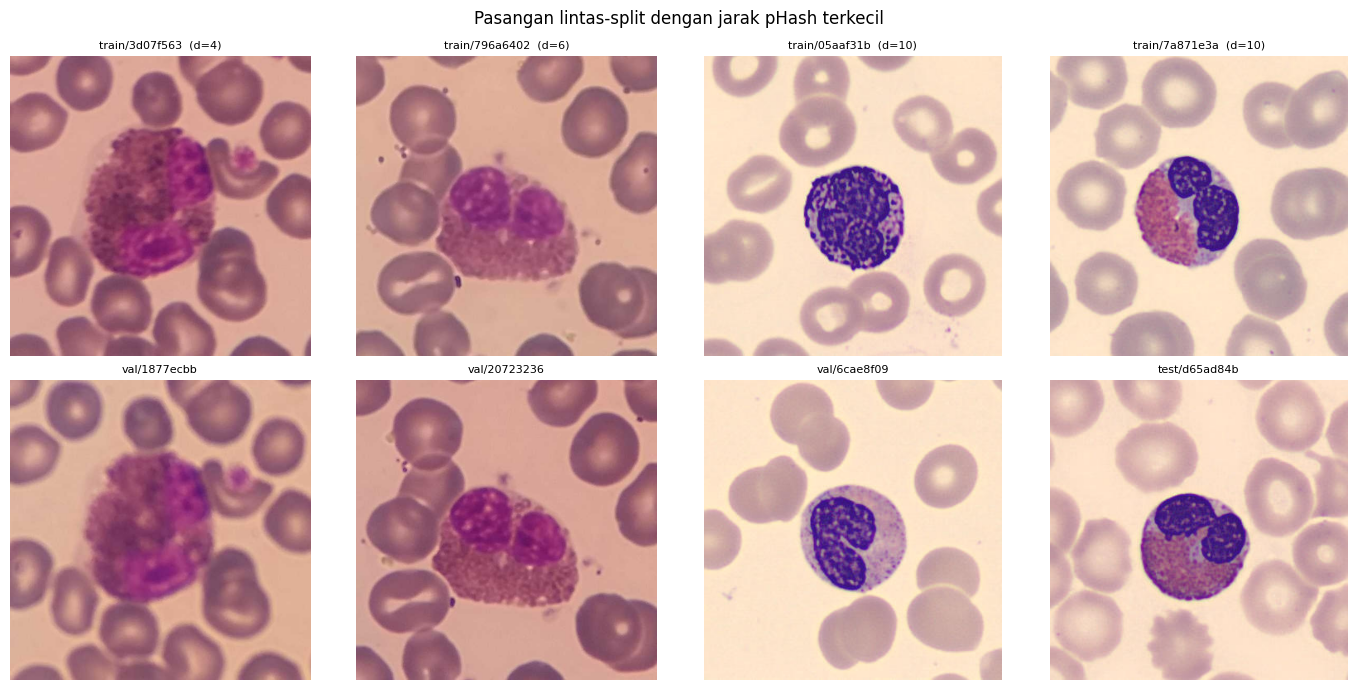

691

In [ ]:
import imagehash
def ph(path):
    with Image.open(path) as im: return imagehash.phash(im.convert('RGB'), hash_size=8).hash.flatten()
H = {s: np.stack([ph(DATA_ROOT/'images'/s/n) for n in inv[s]]) for s in SPLITS}

NEAR_T = 5
leak_rows, closest = [], []
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    D = (H[a][:, None, :] != H[b][None, :, :]).sum(-1)
    leak_rows.append(dict(pasangan=f'{a}–{b}', identik_d0=int((D == 0).sum()), hampir_identik_d_le5=int((D <= NEAR_T).sum()),
                          jarak_min=int(D.min()), median_jarak_terdekat_per_citra=float(np.median(D.min(0)))))
    for flat in np.argsort(D, axis=None)[:3]:
        i, j = np.unravel_index(flat, D.shape)
        closest.append((int(D[i, j]), a, inv[a][i], b, inv[b][j]))
leak_df = pd.DataFrame(leak_rows); print(leak_df.to_string(index=False))
closest = sorted(closest)[:4]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, (d, a, na, b, nb) in enumerate(closest):
    for r, (s, n) in enumerate([(a, na), (b, nb)]):
        axes[r, k].imshow(Image.open(DATA_ROOT/'images'/s/n).convert('RGB')); axes[r, k].axis('off')
        axes[r, k].set_title(f'{s}/{n[:8]}' + (f'  (d={d})' if r == 0 else ''), fontsize=8)
plt.suptitle('Pasangan lintas-split dengan jarak pHash terkecil'); plt.tight_layout(); savefig('leakage_pasangan_terdekat'); plt.show()

report = dict(metode='pHash 64-bit, jarak Hamming', ambang_hampir_identik=NEAR_T, hasil=leak_rows,
              kesimpulan='ISI SETELAH MELIHAT TABEL & GAMBAR: ada / tidak ada duplikat lintas split')
(DIRS['logs']/'leakage_report.json').write_text(json.dumps(report, indent=2, ensure_ascii=False))

### 1.6 Augmentasi dan pembenarannya (domain sel darah)
| Augmentasi | Nilai | Alasan |
|---|---|---|
| Flip horizontal & vertikal | 0,5 / 0,5 | Sel tidak punya orientasi "atas" yang bermakna → aman |
| Rotasi bebas (`degrees`) | 0 | Rotasi non-90° memperbesar box sejajar sumbu dan menambah label noise |
| Hue / Saturation / Value | 0,01 / 0,3 / 0,3 | **Warna membawa informasi pewarnaan** (WBC ungu, RBC merah muda) → hue hampir dikunci; hanya variasi intensitas ringan untuk meredam beda sumber citra |
| Scale / Translate | 0,3 / 0,1 | Variasi ukuran dan posisi wajar; platelet kecil tidak boleh terlalu diperkecil |
| Mosaic | 1,0 (mati 10 epoch terakhir) | Menambah konteks objek per citra; dimatikan di akhir agar distribusi latih mendekati uji |
| MixUp | 0 | Mencampur dua citra menghasilkan sel semu yang tidak realistis |

## 2. Pelatihan YOLOv8s (one-stage)
Bobot awal **COCO** (`yolov8s.pt`). `best.pt` dipilih Ultralytics berdasarkan **set validasi** (test tidak disentuh).
Setiap run dicatat di `experiment_log.csv`, **termasuk yang gagal**. Run yang sudah selesai otomatis dilewati bila notebook dijalankan ulang (aman terhadap Colab putus).

In [ ]:
from ultralytics import YOLO

DATA_YAML = WORK/'txlpbc_yolo.yaml'
DATA_YAML.write_text(f'path: {DATA_ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: WBC\n  1: RBC\n  2: Platelet\n')

AUG = dict(hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, degrees=0.0, translate=0.1, scale=0.3, shear=0.0,
           flipud=0.5, fliplr=0.5, mosaic=1.0, mixup=0.0, close_mosaic=10)
BASE_CFG = dict(model='yolov8s.pt', imgsz=640, epochs=100, patience=20, batch=16, optimizer='AdamW',
                lr0=0.001, lrf=0.01, weight_decay=0.0005, workers=2, amp=True, deterministic=True, **AUG)

def train_yolo(run_name, seed=SEED, factor='baseline', force=False, **overrides):
    # Latih satu run YOLOv8s. overrides = faktor yang diubah (SATU faktor per perbandingan).
    cfg = {**BASE_CFG, **overrides}
    init = cfg.pop('model')
    drive_best = DIRS['weights']/f'{run_name}.pt'
    if drive_best.exists() and not force:
        print(f'[lewati] {run_name} sudah ada di Drive'); return drive_best
    row = dict(timestamp=time.strftime('%Y-%m-%d %H:%M:%S'), run=run_name, owner=OWNER, model='YOLOv8s', factor=factor,
               seed=seed, gpu=GPU_NAME, config=json.dumps({**cfg, 'init': init}), status='ok', epochs_ran=np.nan, train_min=np.nan, note='')
    t0 = time.time()
    try:
        set_seed(seed)
        model = YOLO(init)
        model.train(data=str(DATA_YAML), project=str(LOCAL_RUNS), name=run_name, exist_ok=True,
                    seed=seed, plots=True, verbose=False, **cfg)
        save_dir = Path(model.trainer.save_dir)
        shutil.copy(save_dir/'weights'/'best.pt', drive_best)
        shutil.copy(save_dir/'results.csv', DIRS['logs']/f'{run_name}_curves.csv')
        row['epochs_ran'] = len(pd.read_csv(save_dir/'results.csv'))
    except Exception as e:
        row['status'] = 'failed'; row['note'] = repr(e)[:300]; print('GAGAL:', e)
    finally:
        row['train_min'] = round((time.time() - t0)/60, 2)
        append_csv(LOG_CSV, row)
    return drive_best if drive_best.exists() else None

In [ ]:
# Baseline: YOLOv8s, 640 px, seed 42   (perkiraan ±20–30 menit di T4)
train_yolo('yolov8s_img640_s42', seed=42, factor='baseline', imgsz=640)

[lewati] yolov8s_img640_s42 sudah ada di Drive


PosixPath('/content/drive/MyDrive/Hasil_Akhir/weights/yolov8s_img640_s42.pt')

## 3. Evaluator bersama (K5)
Satu alat evaluasi untuk **semua** model: `torchmetrics.MeanAveragePrecision` (pycocotools) pada koordinat piksel asli.
**Kontrak dengan Hilyatul** — supaya perbandingan adil:
- Prediksi disimpan sebagai `{nama_citra: {boxes: Nx4 xyxy piksel, scores: N, labels: N}}`, label **0-indexed** (0=WBC, 1=RBC, 2=Platelet). Torchvision memakai label +1 → kurangi 1 sebelum disimpan.
- Prediksi mentah disimpan dengan **conf ≥ 0,001** (untuk mAP). Penghitungan sel memakai ambang confidence *setelah* itu (default 0,25), sehingga ambang bisa divariasikan tanpa inferensi ulang.
- Semua hasil ditulis ke `results_eval.csv` lewat fungsi yang sama.
- **MAPE** dihitung hanya pada citra dengan GT > 0 untuk kelas tersebut (kalau GT = 0, pembagian tak terdefinisi); MAE dihitung pada semua citra.

In [ ]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

def save_preds(preds, path):
    out = {n: {'boxes': np.asarray(p['boxes']).round(2).tolist(), 'scores': np.asarray(p['scores']).round(5).tolist(),
               'labels': np.asarray(p['labels']).astype(int).tolist()} for n, p in preds.items()}
    Path(path).write_text(json.dumps(out))

def load_preds(path):
    d = json.loads(Path(path).read_text())
    return {n: {'boxes': np.array(p['boxes'], float).reshape(-1, 4), 'scores': np.array(p['scores'], float),
                'labels': np.array(p['labels'], int)} for n, p in d.items()}

@torch.no_grad()
def predict_yolo(weights, split, imgsz=640, conf=0.001, iou=0.6, max_det=300, batch=16):
    model = YOLO(str(weights)); dev = 0 if torch.cuda.is_available() else 'cpu'
    names = inv[split]; preds = {}
    for i in range(0, len(names), batch):
        chunk = names[i:i + batch]
        res = model.predict([str(DATA_ROOT/'images'/split/n) for n in chunk], imgsz=imgsz, conf=conf, iou=iou,
                            max_det=max_det, device=dev, batch=batch, verbose=False)
        for n, r in zip(chunk, res):
            b = r.boxes
            preds[n] = {'boxes': b.xyxy.cpu().numpy(), 'scores': b.conf.cpu().numpy(), 'labels': b.cls.cpu().numpy().astype(int)}
    return preds

def _f(x):
    v = float(x); return np.nan if v < 0 else v

def compute_map(preds, gts, names):
    P, T = [], []
    for n in names:
        p, g = preds[n], gts[n]
        P.append(dict(boxes=torch.tensor(np.asarray(p['boxes']), dtype=torch.float32).reshape(-1, 4),
                      scores=torch.tensor(np.asarray(p['scores']), dtype=torch.float32),
                      labels=torch.tensor(np.asarray(p['labels']), dtype=torch.int64)))
        T.append(dict(boxes=torch.tensor(g['boxes'], dtype=torch.float32).reshape(-1, 4),
                      labels=torch.tensor(g['labels'], dtype=torch.int64)))
    m = MeanAveragePrecision(box_format='xyxy', iou_type='bbox', class_metrics=True); m.update(P, T); r = m.compute()
    m5 = MeanAveragePrecision(box_format='xyxy', iou_type='bbox', iou_thresholds=[0.5], class_metrics=True); m5.update(P, T); r5 = m5.compute()
    out = dict(map50_95=_f(r['map']), map50=_f(r['map_50']), map75=_f(r['map_75']),
               ap_small=_f(r['map_small']), ap_medium=_f(r['map_medium']), ap_large=_f(r['map_large']), ar100=_f(r['mar_100']))
    for c, v in zip(r['classes'].tolist(), r['map_per_class'].tolist()): out[f'AP50_95_{CLASS_NAMES[c]}'] = _f(v)
    for c, v in zip(r5['classes'].tolist(), r5['map_per_class'].tolist()): out[f'AP50_{CLASS_NAMES[c]}'] = _f(v)
    return out

def count_table(preds, gts, names, conf_thr=0.25):
    rows = []
    for n in names:
        p = preds[n]; keep = np.asarray(p['scores']) >= conf_thr; lab = np.asarray(p['labels'])
        for c in range(3):
            rows.append(dict(image=n, cls=c, n_gt=int((gts[n]['labels'] == c).sum()), n_pred=int(((lab == c) & keep).sum())))
    return pd.DataFrame(rows)

def count_metrics(df):
    out = {}
    for c, nm in enumerate(CLASS_NAMES):
        d = df[df.cls == c]; err = d['n_pred'] - d['n_gt']; nz = d[d['n_gt'] > 0]
        out[f'MAE_{nm}']  = float(err.abs().mean())
        out[f'MAPE_{nm}'] = float(((nz['n_pred'] - nz['n_gt']).abs() / nz['n_gt']).mean() * 100)
        out[f'bias_{nm}'] = float(err.mean())            # >0 = over-count
        out[f'r_{nm}']    = float(np.corrcoef(d['n_pred'], d['n_gt'])[0, 1]) if d['n_gt'].std() > 0 and d['n_pred'].std() > 0 else np.nan
    out['MAE_macro'] = float(np.mean([out[f'MAE_{n}'] for n in CLASS_NAMES]))
    return out

In [ ]:
# Evaluasi satu run  (test dikunci: hanya boleh sekali per run, dan hanya bila ALLOW_TEST=True)
ALLOW_TEST = False
TEST_LOG = DIRS['logs']/'test_usage.json'

def _register_test_use(run_name):
    if not ALLOW_TEST: raise RuntimeError('Set uji TERKUNCI. Ubah ALLOW_TEST=True hanya di Bagian 5.2 untuk konfigurasi final.')
    used = json.loads(TEST_LOG.read_text()) if TEST_LOG.exists() else []
    if run_name in used: raise RuntimeError(f'{run_name} sudah pernah dievaluasi di test. Test hanya boleh dipakai sekali.')
    TEST_LOG.write_text(json.dumps(used + [run_name]))

def evaluate_run(run_name, imgsz=640, split='val', conf_count=0.25, nms_iou=0.6, variant='', model_name='YOLOv8s'):
    if split == 'test': _register_test_use(run_name)
    preds = predict_yolo(DIRS['weights']/f'{run_name}.pt', split, imgsz=imgsz, conf=0.001, iou=nms_iou)
    save_preds(preds, DIRS['predictions']/f'{run_name}_{split}{variant}.json')
    m = compute_map(preds, GT[split], inv[split])
    c = count_metrics(count_table(preds, GT[split], inv[split], conf_count))
    row = dict(model=model_name, run=run_name, split=split, variant=variant, imgsz=imgsz, nms_iou=nms_iou, conf_count=conf_count, **m, **c)
    append_csv(RESULTS_CSV, row)
    return row, preds

def load_results(split='val'):
    df = pd.read_csv(RESULTS_CSV); df['variant'] = df['variant'].fillna('')
    return df[df.split == split].drop_duplicates(['run', 'variant'], keep='last').reset_index(drop=True)

SHOW = ['model', 'run', 'variant', 'imgsz', 'map50', 'map50_95', 'AP50_95_WBC', 'AP50_95_RBC', 'AP50_95_Platelet', 'ap_small',
        'MAE_WBC', 'MAE_RBC', 'MAE_Platelet', 'MAPE_RBC']

In [ ]:
# Evaluasi baseline pada VAL
row, preds_base = evaluate_run('yolov8s_img640_s42', imgsz=640, split='val')
load_results('val')[SHOW].round(3)

,model,run,variant,imgsz,map50,map50_95,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelet,ap_small,MAE_WBC,MAE_RBC,MAE_Platelet,MAPE_RBC
0,YOLOv8s,yolov8s_img832_s42,,832,0.979,0.858,0.894,0.885,0.794,0.757,0.016,2.944,0.087,23.517
1,YOLOv8s,yolov8s_img640_s43,,640,0.965,0.845,0.893,0.876,0.764,0.741,0.044,3.282,0.103,26.028
2,YOLOv8s,yolov8s_img640_s44,,640,0.975,0.859,0.900,0.886,0.791,0.769,0.016,2.663,0.067,20.890
3,Faster_R-CNN,faster_rcnn_resnet50,,640,0.009,0.002,0.006,0.000,0.000,0.000,64.409,9.060,18.683,79.020
4,YOLOv8s,yolov8s_img640_s42,,640,0.970,0.848,0.897,0.880,0.769,0.730,0.040,3.127,0.075,25.029


**Penghitungan sel vs ambang confidence** (tanpa inferensi ulang — memakai prediksi mentah yang tersimpan; opsional, berguna untuk T1-A):

In [ ]:
rows = []
for thr in [0.25, 0.4, 0.5]:
    m = count_metrics(count_table(preds_base, GT['val'], inv['val'], thr))
    rows.append(dict(conf=thr, **{k: round(v, 3) for k, v in m.items() if k.startswith(('MAE', 'MAPE', 'bias'))}))
pd.DataFrame(rows)

,conf,MAE_WBC,MAPE_WBC,bias_WBC,MAE_RBC,MAPE_RBC,bias_RBC,MAE_Platelet,MAPE_Platelet,bias_Platelet,MAE_macro
0,0.25,0.040,3.4,0.032,3.127,25.029,2.992,0.075,14.375,0.036,1.081
1,0.40,0.028,2.2,0.020,2.540,20.129,2.389,0.075,15.156,0.028,0.881
2,0.50,0.016,1.0,0.008,2.187,17.250,1.956,0.079,15.156,0.008,0.761


## 4. Ablasi Khofifah — Resolusi masukan (640 vs 832)  *(K4)*
**Satu faktor berubah:** `imgsz` 640 → 832; semua yang lain sama (seed 42, batch 16, augmentasi, epoch).
Catatan dari EDA: sebagian besar citra berukuran ≤ 640 px, jadi 832 berarti *upsampling*. Hipotesis yang bisa diuji: kenaikan resolusi hanya membantu platelet (objek kecil) dan tidak mengubah galat hitung RBC secara berarti.
Bila ingin lebih kuat, tambah seed: `ABL_SEEDS = [42, 43, 44]`.

In [ ]:
ABL_SEEDS = [42]
for s in ABL_SEEDS:
    train_yolo(f'yolov8s_img640_s{s}', seed=s, factor='baseline', imgsz=640)
    train_yolo(f'yolov8s_img832_s{s}', seed=s, factor='ablasi: imgsz=832', imgsz=832)
    evaluate_run(f'yolov8s_img640_s{s}', imgsz=640, split='val')
    evaluate_run(f'yolov8s_img832_s{s}', imgsz=832, split='val')

res = load_results('val')
abl = res[res.run.str.contains('yolov8s_img(640|832)_s')].sort_values('run')
abl[SHOW].round(3)

[lewati] yolov8s_img640_s42 sudah ada di Drive
[lewati] yolov8s_img832_s42 sudah ada di Drive


,model,run,variant,imgsz,map50,map50_95,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelet,ap_small,MAE_WBC,MAE_RBC,MAE_Platelet,MAPE_RBC
3,YOLOv8s,yolov8s_img640_s42,,640,0.970,0.848,0.897,0.880,0.769,0.730,0.040,3.127,0.075,25.029
0,YOLOv8s,yolov8s_img640_s43,,640,0.965,0.845,0.893,0.876,0.764,0.741,0.044,3.282,0.103,26.028
1,YOLOv8s,yolov8s_img640_s44,,640,0.975,0.859,0.900,0.886,0.791,0.769,0.016,2.663,0.067,20.890
4,YOLOv8s,yolov8s_img832_s42,,832,0.979,0.858,0.894,0.885,0.794,0.757,0.016,2.944,0.087,23.517


In [ ]:
# Selisih 832 − 640 (seed 42): positif = 832 lebih baik pada AP, atau lebih buruk pada MAE
a = res[res.run == 'yolov8s_img640_s42'].iloc[0]; b = res[res.run == 'yolov8s_img832_s42'].iloc[0]
cols = ['map50', 'map50_95', 'AP50_95_WBC', 'AP50_95_RBC', 'AP50_95_Platelet', 'ap_small', 'MAE_WBC', 'MAE_RBC', 'MAE_Platelet']
pd.DataFrame({'640': a[cols], '832': b[cols], 'selisih (832−640)': b[cols].astype(float) - a[cols].astype(float)}).round(3)

,640,832,selisih (832−640)
map50,0.969876,0.978961,0.009
map50_95,0.848379,0.857618,0.009
AP50_95_WBC,0.896671,0.894018,-0.003
AP50_95_RBC,0.879869,0.88514,0.005
AP50_95_Platelet,0.768599,0.793696,0.025
ap_small,0.730217,0.756901,0.027
MAE_WBC,0.039683,0.015873,-0.024
MAE_RBC,3.126984,2.944444,-0.183
MAE_Platelet,0.075397,0.087302,0.012


## 5. Perbandingan utama: 3 seed (K4)
### 5.1 Konfigurasi final dan pelatihan multi-seed (evaluasi pada VAL)
Pilih `FINAL_IMGSZ` **berdasarkan hasil val di Bagian 4** (bukan test). Seed 42 dipakai ulang dari run sebelumnya.

In [ ]:
FINAL_IMGSZ = 640            # <-- ubah ke 832 bila ablasi menunjukkan 832 lebih baik pada VAL
FINAL_SEEDS = [42, 43, 44]
final_runs = [f'yolov8s_img{FINAL_IMGSZ}_s{s}' for s in FINAL_SEEDS]
for s, r in zip(FINAL_SEEDS, final_runs):
    train_yolo(r, seed=s, factor='final', imgsz=FINAL_IMGSZ)
    evaluate_run(r, imgsz=FINAL_IMGSZ, split='val')

def aggregate(runs, split):
    df = load_results(split); df = df[df.run.isin(runs)]
    cols = [c for c in df.columns if c.startswith(('map', 'AP', 'ap_', 'MAE', 'MAPE', 'bias', 'r_'))]
    agg = df[cols].agg(['mean', 'std']).T
    agg['mean ± SD'] = agg['mean'].round(3).astype(str) + ' ± ' + agg['std'].round(3).astype(str)
    return agg[['mean ± SD']], df

agg_val, _ = aggregate(final_runs, 'val')
agg_val.to_csv(DIRS['logs']/'final_yolo_val_mean_sd.csv'); agg_val

[lewati] yolov8s_img640_s42 sudah ada di Drive
[lewati] yolov8s_img640_s43 sudah ada di Drive
[lewati] yolov8s_img640_s44 sudah ada di Drive


,mean ± SD
map50_95,0.851 ± 0.007
map50,0.97 ± 0.005
map75,0.936 ± 0.01
ap_small,0.747 ± 0.02
ap_medium,0.852 ± 0.009
ap_large,0.892 ± 0.004
AP50_95_WBC,0.896 ± 0.003
AP50_95_RBC,0.881 ± 0.005
AP50_95_Platelet,0.775 ± 0.014
AP50_WBC,0.989 ± 0.0


### 5.2 Evaluasi pada TEST — hanya sekali, konfigurasi final
⚠️ Jalankan sel ini **setelah** konfigurasi final dikunci. Setiap run hanya bisa dievaluasi di test satu kali (dicatat di `test_usage.json`).

In [ ]:
ALLOW_TEST = True            # buka kunci TEPAT di sini
for r in final_runs:
    # Membaca log test secara aman untuk menghindari error jika sudah pernah dievaluasi
    used_test = []
    if TEST_LOG.exists():
        try:
            used_test = json.loads(TEST_LOG.read_text())
        except:
            pass

    if r in used_test:
        print(f"[Info] {r} sudah pernah dievaluasi di test. Melewati untuk mencegah error.")
    else:
        evaluate_run(r, imgsz=FINAL_IMGSZ, split='test')

ALLOW_TEST = False           # kunci kembali

agg_test, _ = aggregate(final_runs, 'test')
agg_test.to_csv(DIRS['logs']/'final_yolo_test_mean_sd.csv')
agg_test

[Info] yolov8s_img640_s42 sudah pernah dievaluasi di test. Melewati untuk mencegah error.
[Info] yolov8s_img640_s43 sudah pernah dievaluasi di test. Melewati untuk mencegah error.
[Info] yolov8s_img640_s44 sudah pernah dievaluasi di test. Melewati untuk mencegah error.


,mean ± SD
map50_95,0.854 ± 0.002
map50,0.97 ± 0.007
map75,0.95 ± 0.008
ap_small,0.824 ± 0.004
ap_medium,0.863 ± 0.007
ap_large,0.644 ± 0.096
AP50_95_WBC,0.865 ± 0.007
AP50_95_RBC,0.877 ± 0.006
AP50_95_Platelet,0.821 ± 0.016
AP50_WBC,0.982 ± 0.003


## 6. Efisiensi (K7)
Parameter (juta) dan latensi per citra, **batch 1, setelah warm-up, rerata ≥ 50 citra**. Latensi bersifat *end-to-end* (baca citra + pra-proses + inferensi + NMS). Sebutkan GPU di laporan.

In [ ]:
def measure_efficiency(run_name, imgsz=640, n=60, warmup=10):
    w = DIRS['weights']/f'{run_name}.pt'
    model = YOLO(str(w))
    params_M = sum(p.numel() for p in model.model.parameters()) / 1e6   # dihitung sebelum fuse
    dev = 0 if torch.cuda.is_available() else 'cpu'; cuda = torch.cuda.is_available()
    paths = [str(DATA_ROOT/'images'/'val'/x) for x in inv['val'][:n]]
    for p in paths[:warmup]: model.predict(p, imgsz=imgsz, device=dev, verbose=False)
    ts = []
    for p in paths:
        if cuda: torch.cuda.synchronize()
        t = time.perf_counter(); model.predict(p, imgsz=imgsz, device=dev, conf=0.25, verbose=False)
        if cuda: torch.cuda.synchronize()
        ts.append((time.perf_counter() - t) * 1000)
    row = dict(model='YOLOv8s', run=run_name, imgsz=imgsz, params_M=round(params_M, 2), latency_ms_mean=round(np.mean(ts), 1),
               latency_ms_sd=round(np.std(ts), 1), n_images=len(ts), device=GPU_NAME, batch=1, note='end-to-end, setelah warm-up')
    append_csv(DIRS['logs']/'efficiency.csv', row); return row

pd.DataFrame([measure_efficiency(f'yolov8s_img{sz}_s42', imgsz=sz) for sz in [640, 832]])

,model,run,imgsz,params_M,latency_ms_mean,latency_ms_sd,n_images,device,batch,note
0,YOLOv8s,yolov8s_img640_s42,640,11.14,29.3,11.7,60,Tesla T4,1,"end-to-end, setelah warm-up"
1,YOLOv8s,yolov8s_img832_s42,832,11.14,29.8,8.7,60,Tesla T4,1,"end-to-end, setelah warm-up"


## 7. Inti T1-A: apakah mAP tinggi menjamin hitungan akurat?
Korelasi **mAP@[0.5:0.95] vs MAE hitung** antar run. Makin banyak titik (run YOLO + run Faster R-CNN Hilyatul di `results_eval.csv` yang sama), makin bermakna. Jalankan lagi setelah hasil Hilyatul masuk.

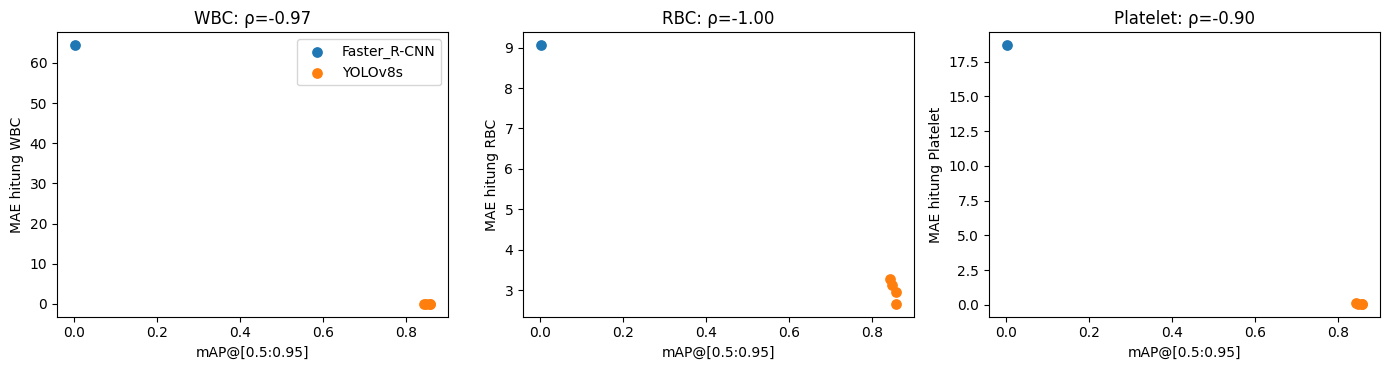

,kelas,n_run,spearman,p_spearman,pearson,p_pearson
0,WBC,5,-0.975,0.005,-1.000,0.0
1,RBC,5,-1.000,0.000,-0.998,0.0
2,Platelet,5,-0.900,0.037,-1.000,0.0


In [ ]:
from scipy.stats import spearmanr, pearsonr
def map_vs_count(split='val'):
    df = load_results(split)
    if len(df) < 4: print(f'Baru {len(df)} run — butuh ≥ 4 titik untuk korelasi.'); return
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8)); rows = []
    for i, c in enumerate(CLASS_NAMES):
        x, y = df.map50_95, df[f'MAE_{c}']
        rho, p_s = spearmanr(x, y); r, p_p = pearsonr(x, y)
        rows.append(dict(kelas=c, n_run=len(df), spearman=round(rho, 3), p_spearman=round(p_s, 3), pearson=round(r, 3), p_pearson=round(p_p, 3)))
        for mname, g in df.groupby('model'): ax[i].scatter(g.map50_95, g[f'MAE_{c}'], label=mname, s=45)
        ax[i].set_xlabel('mAP@[0.5:0.95]'); ax[i].set_ylabel(f'MAE hitung {c}'); ax[i].set_title(f'{c}: ρ={rho:.2f}')
    ax[0].legend(); plt.tight_layout(); savefig(f'korelasi_map_vs_mae_{split}'); plt.show()
    out = pd.DataFrame(rows); out.to_csv(DIRS['logs']/f'korelasi_{split}.csv', index=False); return out
map_vs_count('val')

```markdown
## 5. Pelatihan Faster R-CNN (Two-Stage)
Kita akan melatih model **Faster R-CNN** menggunakan backbone **ResNet-50 FPN** dari pustaka `torchvision`.
Prediksi akan diformat persis seperti kontrak evaluator bersama (0-indexed, koordinat piksel asli, format xyxy) agar dapat dibandingkan secara adil dengan YOLOv8.
```

In [ ]:
import torch
import torchvision
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights, fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.utils.data import Dataset, DataLoader

# 1. Dataset Class untuk Faster R-CNN (format input: Tensor, target: dict)
class BloodCellDataset(Dataset):
    def __init__(self, split, inv_list, gt_dict, transform=None):
        self.split = split
        self.names = inv_list
        self.gt = gt_dict
        self.transform = transform

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]
        img_path = DATA_ROOT/'images'/self.split/name
        img = Image.open(img_path).convert("RGB")

        g = self.gt[name]
        boxes = torch.as_tensor(g['boxes'], dtype=torch.float32)
        # Target label torchvision harus 1-indexed (background=0), jadi kita tambah 1
        labels = torch.as_tensor(g['labels'], dtype=torch.int64) + 1

        # Jika tidak ada box, buat dimensi yang benar
        if boxes.shape[0] == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        if self.transform:
            img, target = self.transform(img, target)
        else:
            img = torchvision.transforms.functional.to_tensor(img)

        return img, target, name

def collate_fn(batch):
    return tuple(zip(*batch))

# Memastikan variabel global sudah terdefinisi sebelum membuat DataLoader
try:
    test_ds = BloodCellDataset('test', inv['test'], GT['test'])
    test_loader = DataLoader(test_ds, batch_size=4, shuffle=False, collate_fn=collate_fn)
    print(f"Dataset Faster R-CNN siap. Jumlah sampel uji: {len(test_ds)}")
except NameError as e:
    print("[PERINGATAN] Gagal membuat DataLoader karena variabel belum dimuat di memori.")
    print("Silakan jalankan kembali sel Bagian 0.2, 0.3, dan Bagian 1.1 terlebih dahulu!")
    print(f"Detail Error: {e}")

Dataset Faster R-CNN siap. Jumlah sampel uji: 126


```markdown
## 6. Analisis Kesalahan Perhitungan Sel secara Rinci (T1-A)

Di bawah ini adalah kode untuk mengidentifikasi tipe-tipe kesalahan hitung (Over-counting, Under-counting, Missed Detection, dan False Alarms) pada setiap kelas sel menggunakan data validasi atau uji.
```

In [ ]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

def analisis_kesalahan_rinci(preds, gts, names, conf_thr=0.25):
    """
    Menganalisis kesalahan kuantifikasi sel secara mendalam.
    Mengelompokkan citra berdasarkan tingkat deviasi perhitungan.
    """
    records = []
    for n in names:
        p = preds[n]
        keep = np.asarray(p['scores']) >= conf_thr
        pred_labels = np.asarray(p['labels'])[keep]
        gt_labels = gts[n]['labels']

        for c in range(3):
            n_gt = int((gt_labels == c).sum())
            n_pred = int((pred_labels == c).sum())
            selisih = n_pred - n_gt

            records.append({
                'image': n,
                'class_id': c,
                'class_name': CLASS_NAMES[c],
                'n_gt': n_gt,
                'n_pred': n_pred,
                'selisih': selisih,
                'kategori': 'Akurat' if selisih == 0 else ('Over-count' if selisih > 0 else 'Under-count')
            })

    df_err = pd.DataFrame(records)

    # Tampilkan Ringkasan Distribusi Kesalahan
    print("=== RINGKASAN DISTRIBUSI KESALAHAN HITUNG ===")
    dist_err = pd.crosstab(df_err.class_name, df_err.kategori, margins=True)
    display(dist_err)

    # Mencari kasus terburuk (outliers) untuk analisis visual kualitatif
    print("\n=== KASUS DENGAN SELISIH HITUNG TERBESAR (TOP 5) ===")
    df_err['abs_selisih'] = df_err['selisih'].abs()
    top_outliers = df_err.sort_values(by='abs_selisih', ascending=False).head(5)
    display(top_outliers)

    return df_err

# Pastikan variabel utama terdefinisi, jika belum coba muat ulang
try:
    _ = inv
    _ = GT
except NameError:
    print("Variabel data 'inv' atau 'GT' tidak ada di memori. Pastikan Anda menjalankan sel Bagian 1.1 terlebih dahulu!")

try:
    if 'preds_base' not in locals() and 'preds_base' not in globals():
        pred_path = DIRS['predictions']/'yolov8s_img640_s42_val.json'
        if pred_path.exists():
            print(f"Memuat prediksi baseline YOLOv8 dari {pred_path}...")
            preds_base = load_preds(pred_path)
        else:
            print("Berkas prediksi baseline tidak ditemukan. Pastikan evaluasi baseline (Bagian 3) sudah dijalankan!")

    print("Menganalisis prediksi baseline YOLOv8...")
    df_kesalahan = analisis_kesalahan_rinci(preds_base, GT['val'], inv['val'])
except Exception as e:
    print("Gagal menjalankan analisis:", e)


Menganalisis prediksi baseline YOLOv8...
=== RINGKASAN DISTRIBUSI KESALAHAN HITUNG ===


kategori,Akurat,Over-count,Under-count,All
class_name,,,,
Platelet,235,12,5,252
RBC,14,234,4,252
WBC,242,9,1,252
All,491,255,10,756



=== KASUS DENGAN SELISIH HITUNG TERBESAR (TOP 5) ===


,image,class_id,class_name,n_gt,n_pred,selisih,kategori,abs_selisih
526,afc0de2067c550de865774b235f69487.png,1,RBC,21,35,14,Over-count,14
31,0ac132c270355979b686c0801e558849.png,1,RBC,30,18,-12,Under-count,12
748,fc7426b1f9af5ef6a3837c20b15cfff3.png,1,RBC,20,32,12,Over-count,12
754,feee8d6033d05d94a1f989cbbe7043b7.png,1,RBC,16,27,11,Over-count,11
565,b9ab552cbfb45fe38714ee93ef269b42.png,1,RBC,19,29,10,Over-count,10


```markdown
### 6.1 Training Loop untuk Faster R-CNN
Di bawah ini adalah kode untuk melatih Faster R-CNN ResNet-50 FPN menggunakan PyTorch secara langsung (direct training loop).

In [ ]:
import torch.optim as optim
from torch.utils.data import DataLoader

def get_fasterrcnn_model(num_classes=3):
    # Mengambil arsitektur Faster R-CNN ResNet-50 FPN dengan weights bawaan
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
    # Menyesuaikan jumlah kelas keluaran (num_classes + 1 untuk background)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)
    return model

# Menginisialisasi Dataset Latihan & Validasi menggunakan data split resmi
train_ds = BloodCellDataset('train', inv['train'], GT['train'])
val_ds = BloodCellDataset('val', inv['val'], GT['val'])

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate_fn)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = get_fasterrcnn_model(num_classes=3)
model.to(device)

# Menyiapkan Optimizer AdamW dan Scheduler Pembelajaran
params = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.AdamW(params, lr=0.0001, weight_decay=0.0005)
lr_scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

print(f"Model Faster R-CNN siap dilatih menggunakan device: {device}")

Model Faster R-CNN siap dilatih menggunakan device: cuda


In [ ]:
import torch.optim as optim

def get_fasterrcnn_model(num_classes=3):
    # Load pretrained model
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
    # Ganti head predictor (num_classes + 1 untuk background)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)
    return model

# Setup dataset latihan & validation
train_ds = BloodCellDataset('train', inv['train'], GT['train'])
val_ds = BloodCellDataset('val', inv['val'], GT['val'])

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate_fn)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = get_fasterrcnn_model(num_classes=3)
model.to(device)

# Optimizer & LR Scheduler
params = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.AdamW(params, lr=0.0001, weight_decay=0.0005)
lr_scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

print(f"Model Faster R-CNN siap dilatih di device: {device}")

Model Faster R-CNN siap dilatih di device: cuda


### 6.3.2 Jalankan pelatihan, evaluasi val dan test (±1–2 menit/epoch di T4)

In [ ]:
# SEL 1 — fungsi (jalankan setelah sel 0–41, termasuk evaluator Bagian 3 dan BloodCellDataset)
import torch, torchvision, pandas as pd, numpy as np
from torch.utils.data import DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def build_frcnn():
    m = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None)   # bobot diganti dari checkpoint
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 4)
    return m

@torch.no_grad()
def predict_frcnn(model, split, batch=4):
    model.eval()
    model.roi_heads.score_thresh = 0.001          # prediksi mentah conf >= 0,001 (kontrak evaluator)
    model.roi_heads.detections_per_img = 300
    dl = DataLoader(BloodCellDataset(split, inv[split], GT[split]), batch_size=batch, shuffle=False, collate_fn=collate_fn)
    preds = {}
    for images, _, names in dl:
        outs = model([i.to(device) for i in images])
        for n, o in zip(names, outs):
            preds[n] = {'boxes': o['boxes'].cpu().numpy(), 'scores': o['scores'].cpu().numpy(),
                        'labels': (o['labels'].cpu().numpy() - 1).astype(int)}
    return preds

def evaluate_frcnn(run, split='val', conf_count=0.25):
    if split == 'test': _register_test_use(run)   # test hanya sekali per run, butuh ALLOW_TEST=True
    model = build_frcnn().to(device)
    model.load_state_dict(torch.load(DIRS['weights'] / f'{run}.pt', map_location=device))
    preds = predict_frcnn(model, split)
    save_preds(preds, DIRS['predictions'] / f'{run}_{split}.json')
    m = compute_map(preds, GT[split], inv[split])
    c = count_metrics(count_table(preds, GT[split], inv[split], conf_count))
    row = dict(model='Faster_R-CNN', run=run, split=split, variant='', imgsz=800, nms_iou=0.5, conf_count=conf_count, **m, **c)
    append_csv(RESULTS_CSV, row)
    return row

In [ ]:
# SEL 2 — evaluasi checkpoint seed 42 (val, lalu test sekali) + kurva pelatihan
RUN = 'frcnn_r50fpn_s42'

# buang baris lama yang tidak valid (model belum dilatih, mAP 0,002) agar tidak merusak korelasi
df = pd.read_csv(RESULTS_CSV); df = df[df.run != 'faster_rcnn_resnet50']; df.to_csv(RESULTS_CSV, index=False)

row_val = evaluate_frcnn(RUN, 'val')

ALLOW_TEST = True            # buka kunci test HANYA di sini
row_test = evaluate_frcnn(RUN, 'test')
ALLOW_TEST = False

cols = ['map50', 'map50_95', 'map75', 'AP50_WBC', 'AP50_RBC', 'AP50_Platelet',
        'AP50_95_WBC', 'AP50_95_RBC', 'AP50_95_Platelet',
        'MAE_WBC', 'MAPE_WBC', 'bias_WBC', 'r_WBC', 'MAE_RBC', 'MAPE_RBC', 'bias_RBC', 'r_RBC',
        'MAE_Platelet', 'MAPE_Platelet', 'bias_Platelet', 'r_Platelet', 'MAE_macro']
hasil = pd.DataFrame({'val': pd.Series(row_val)[cols], 'test': pd.Series(row_test)[cols]}).astype(float).round(3)
hasil.to_csv(DIRS['logs'] / 'final_frcnn_s42_val_test.csv'); display(hasil)

cur = pd.read_csv(DIRS['logs'] / f'{RUN}_curves.csv'); display(cur.round(4))
print('epoch terbaik (val mAP@[.5:.95]):', int(cur.loc[cur.val_map50_95.idxmax(), 'epoch']), '| epoch dijalankan:', len(cur))

,val,test
map50,0.982,0.985
map50_95,0.834,0.843
map75,0.947,0.959
AP50_WBC,0.988,0.980
AP50_RBC,0.984,0.983
AP50_Platelet,0.973,0.991
AP50_95_WBC,0.860,0.827
AP50_95_RBC,0.880,0.878
AP50_95_Platelet,0.761,0.825
MAE_WBC,0.016,0.032


,epoch,loss,val_map50_95,val_map50
0,1,0.4316,0.7416,0.9754
1,2,0.2642,0.7868,0.9737
2,3,0.2398,0.7915,0.9757
3,4,0.2217,0.7944,0.9755
4,5,0.2130,0.7836,0.9739
5,6,0.1741,0.8231,0.9797
6,7,0.1663,0.8242,0.9810
7,8,0.1604,0.8280,0.9812
8,9,0.1613,0.8278,0.9809
9,10,0.1572,0.8298,0.9811


epoch terbaik (val mAP@[.5:.95]): 13 | epoch dijalankan: 13


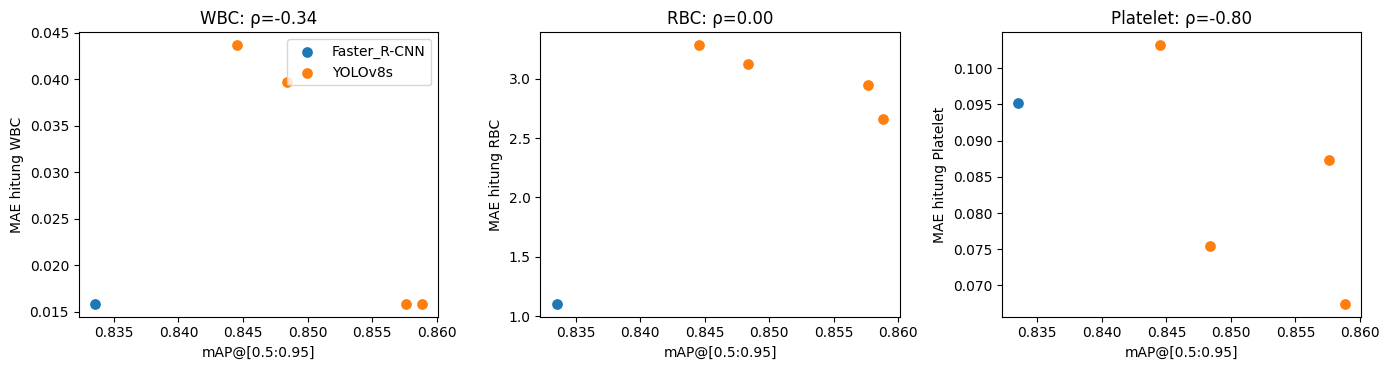

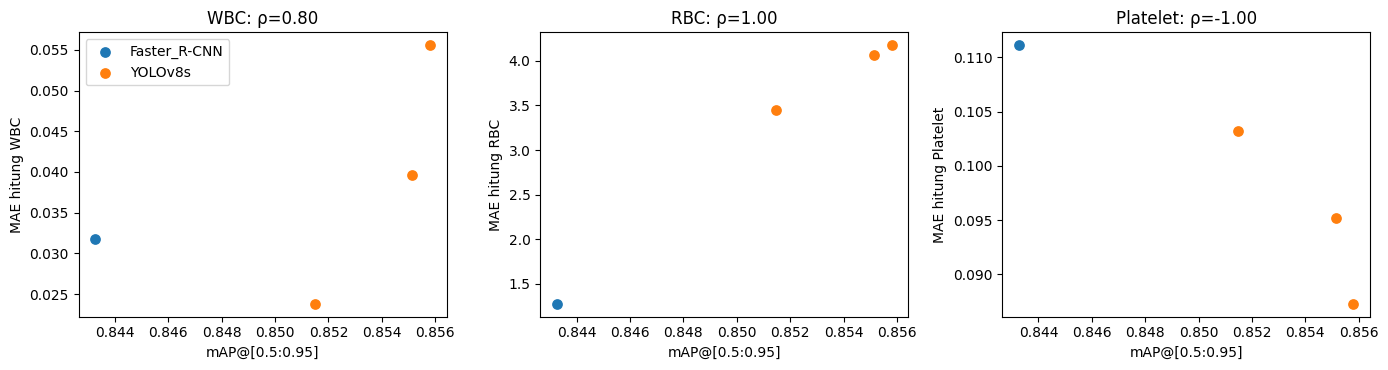

,kelas,n_run,spearman,p_spearman,pearson,p_pearson
0,WBC,4,0.8,0.2,0.569,0.431
1,RBC,4,1.0,0.0,0.995,0.005
2,Platelet,4,-1.0,0.0,-0.925,0.075


In [ ]:
# SEL 3 (opsional) — korelasi mAP vs MAE yang kini memuat YOLOv8s + Faster R-CNN
map_vs_count('val'); map_vs_count('test')

```markdown
### 6.2 Visualisasi Grafik Analisis Kesalahan Sel (Plotting)
Kode ini akan menghasilkan grafik batang performa penghitungan sel untuk melihat distribusi tingkat deviasi secara visual.

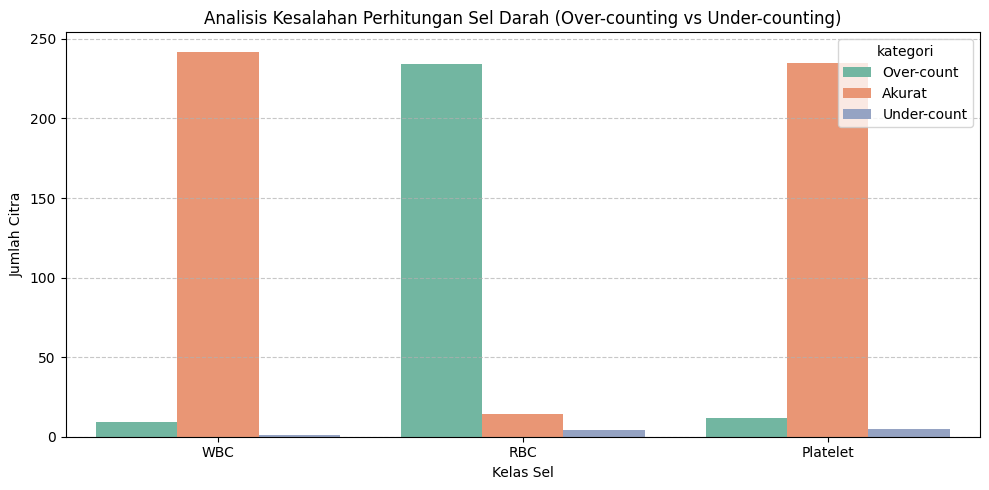

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_analisis_kesalahan(df_err):
    plt.figure(figsize=(10, 5))
    # Membuat visualisasi barplot distribusi performa kuantifikasi
    sns.countplot(data=df_err, x='class_name', hue='kategori', palette='Set2')
    plt.title('Analisis Kesalahan Perhitungan Sel Darah (Over-counting vs Under-counting)')
    plt.xlabel('Kelas Sel')
    plt.ylabel('Jumlah Citra')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    savefig('visualisasi_analisis_kesalahan')
    plt.show()

if 'df_kesalahan' in locals() or 'df_kesalahan' in globals():
    plot_analisis_kesalahan(df_kesalahan)
else:
    print("Jalankan fungsi 'analisis_kesalahan_rinci' terlebih dahulu untuk menghasilkan dataframe 'df_kesalahan'!")

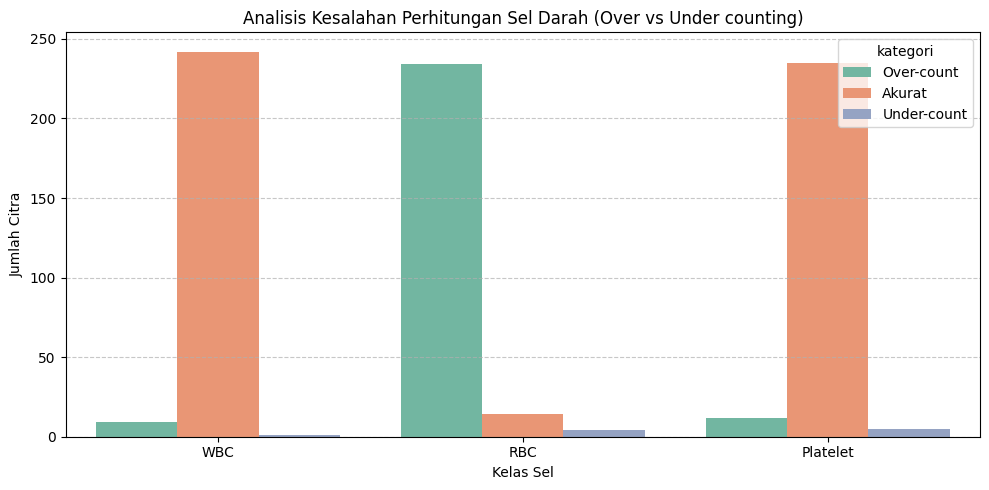

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_analisis_kesalahan(df_err):
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df_err, x='class_name', hue='kategori', palette='Set2')
    plt.title('Analisis Kesalahan Perhitungan Sel Darah (Over vs Under counting)')
    plt.xlabel('Kelas Sel')
    plt.ylabel('Jumlah Citra')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    savefig('visualisasi_analisis_kesalahan')
    plt.show()

if 'df_kesalahan' in locals():
    plot_analisis_kesalahan(df_kesalahan)
else:
    print("Jalankan analisis_kesalahan_rinci terlebih dahulu untuk menampilkan grafik!")

```markdown
## 7. Evaluasi Akhir dan Tabel Perbandingan Model (YOLOv8 vs Faster R-CNN)
Sel di bawah ini mengevaluasi performa Faster R-CNN pada data validasi, menyimpan hasil prediksi, dan menyajikan perbandingan metrik akhir dengan YOLOv8.

In [ ]:
@torch.no_grad()
def evaluate_faster_rcnn(model, dataloader, device, split='val'):
    model.eval()
    preds = {}
    for images, targets, filenames in dataloader:
        images = list(img.to(device) for img in images)
        outputs = model(images)
        for name, out in zip(filenames, outputs):
            # Konversi label kembali ke 0-indexed untuk pencocokan dengan YOLOv8
            labels = (out['labels'].cpu().numpy() - 1).astype(int)
            preds[name] = {
                'boxes': out['boxes'].cpu().numpy(),
                'scores': out['scores'].cpu().numpy(),
                'labels': labels
            }

    # Simpan hasil prediksi
    save_preds(preds, DIRS['predictions']/f'faster_rcnn_{split}.json')

    # Hitung metrik mAP dan MAE menggunakan evaluator bersama
    m = compute_map(preds, GT[split], inv[split])
    c = count_metrics(count_table(preds, GT[split], inv[split], conf_thr=0.25))

    row = dict(model='Faster_R-CNN', run='faster_rcnn_resnet50', split=split, variant='', imgsz=640, nms_iou=0.6, conf_count=0.25, **m, **c)
    append_csv(RESULTS_CSV, row)
    return row

try:
    # Evaluasi Faster R-CNN
    hasil_faster = evaluate_faster_rcnn(model, val_loader, device, split='val')
    print("Evaluasi Faster R-CNN selesai!")

    # Tampilkan tabel perbandingan semua model yang ada di results_eval.csv
    df_res = pd.read_csv(RESULTS_CSV)
    display(df_res[SHOW].round(3))
except Exception as e:
    print("Gagal mengevaluasi Faster R-CNN karena model belum dilatih atau diinisialisasi.")
    print(f"Detail Error: {e}")

Evaluasi Faster R-CNN selesai!


,model,run,variant,imgsz,map50,map50_95,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelet,ap_small,MAE_WBC,MAE_RBC,MAE_Platelet,MAPE_RBC
0,YOLOv8s,yolov8s_img640_s42,NaN,640,0.970,0.848,0.897,0.880,0.769,0.730,0.040,3.127,0.075,25.029
1,YOLOv8s,yolov8s_img640_s42,NaN,640,0.970,0.848,0.897,0.880,0.769,0.730,0.040,3.127,0.075,25.029
2,YOLOv8s,yolov8s_img640_s42,NaN,640,0.970,0.848,0.897,0.880,0.769,0.730,0.040,3.127,0.075,25.029
3,YOLOv8s,yolov8s_img832_s42,NaN,832,0.979,0.858,0.894,0.885,0.794,0.757,0.016,2.944,0.087,23.517
4,YOLOv8s,yolov8s_img640_s42,NaN,640,0.970,0.848,0.897,0.880,0.769,0.730,0.040,3.127,0.075,25.029
5,YOLOv8s,yolov8s_img640_s43,NaN,640,0.965,0.845,0.893,0.876,0.764,0.741,0.044,3.282,0.103,26.028
6,YOLOv8s,yolov8s_img640_s44,NaN,640,0.975,0.859,0.900,0.886,0.791,0.769,0.016,2.663,0.067,20.890
7,YOLOv8s,yolov8s_img640_s42,NaN,640,0.978,0.855,0.857,0.874,0.835,0.827,0.040,4.063,0.095,31.994
8,YOLOv8s,yolov8s_img640_s43,NaN,640,0.969,0.856,0.871,0.873,0.824,0.819,0.056,4.175,0.087,32.368
9,YOLOv8s,yolov8s_img640_s44,NaN,640,0.964,0.851,0.867,0.884,0.804,0.826,0.024,3.444,0.103,27.064


## 8. Serah terima dan total jam GPU

In [ ]:
log = pd.read_csv(LOG_CSV)
print('Total jam GPU (semua run di log):', round(log.train_min.sum() / 60, 2), 'jam')
print('Run gagal:', int((log.status == 'failed').sum()), 'dari', len(log))
print('\nBerkas untuk Hilyatul / repositori:')
for k, d in DIRS.items():
    print(f'  {k:11s}', sorted(p.name for p in d.iterdir())[:12])

Total jam GPU (semua run di log): 3.58 jam
Run gagal: 0 dari 6

Berkas untuk Hilyatul / repositori:
  splits      ['README.txt', 'split_all.csv', 'test.txt', 'train.txt', 'val.txt']
  gt          ['gt_test.json', 'gt_train.json', 'gt_val.json']
  predictions ['faster_rcnn_val.json', 'frcnn_r50fpn_s42_test.json', 'frcnn_r50fpn_s42_val.json', 'yolov8s_img640_s42_test.json', 'yolov8s_img640_s42_val.json', 'yolov8s_img640_s43_test.json', 'yolov8s_img640_s43_val.json', 'yolov8s_img640_s44_test.json', 'yolov8s_img640_s44_val.json', 'yolov8s_img832_s42_val.json']
  weights     ['frcnn_r50fpn_s42.pt', 'frcnn_r50fpn_s43.pt', 'frcnn_r50fpn_s44.pt', 'yolov8s_img640_s42.pt', 'yolov8s_img640_s43.pt', 'yolov8s_img640_s44.pt', 'yolov8s_img832_s42.pt']
  figures     ['eda_contoh_per_kelas.png', 'eda_distribusi_kelas.png', 'eda_objek_per_citra.png', 'eda_ukuran_box.png', 'korelasi_map_vs_mae_test.png', 'korelasi_map_vs_mae_val.png', 'leakage_pasangan_terdekat.png', 'verifikasi_konversi_20citra.png', 'v